# Imports

In [1]:
# Jupyter Notebook Utils
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Python Libraries
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from statsmodels.stats import diagnostic
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Own modules
from src import *

# Data Sanity Check

In [2]:
check_quality(interactions_df)
check_quality(embeddings_subreddits_df)
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [3]:
interactions_df

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.00,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,body
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,101.0,98.0,0.742574,0.019802,0.049505,...,0.066667,0.00,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,body
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,85.0,85.0,0.752941,0.023529,0.082353,...,0.000000,0.00,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,body
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.00,0.0,0.0,0.0,0.0,0.0,0.020833,0.005208,body
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,715.0,622.0,0.777622,0.006993,0.025175,...,0.025000,0.00,0.0,0.0,0.0,0.0,0.0,0.000000,0.008333,body
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
858483,seattleshitshow,seattlewa,68iptp,2017-04-27 11:07:31,-1,83.0,70.0,0.783133,0.000000,0.108434,...,0.000000,0.00,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,title
858484,peoplewhosayheck,spiderman,68iqh6s,2017-04-30 16:36:07,1,121.0,105.0,0.719008,0.016529,0.099174,...,0.050000,0.00,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,title
858485,vzla,wtf,68iqkcs,2017-04-30 15:50:07,1,68.0,58.0,0.764706,0.000000,0.147059,...,0.000000,0.00,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,title
858486,denverbroncos,nfl,68iqt8,2017-04-30 16:11:30,-1,96.0,79.0,0.770833,0.000000,0.072917,...,0.000000,0.05,0.0,0.0,0.0,0.0,0.0,0.000000,0.050000,title


# Patient-0 Analysis

## Data Focusing tool

In order to identify the patient 0, we first construct a tool capable of focusing on a time window and on links which contain a specific keyword. This allows us to dig into a more relevant part of the data, and therefore identify more easily trends in a given context. 

We highlight that this method is meant to help faster identification of trends, and that a more rigorous causal analysis will be conducted later on. This is important as this tool may focus too much on parts of the data, and thus eliminate precursors without eliminating their effect. In instance, the actual patient zero subreddit or community might not contain the chosen given in its name, leaving the possibility of having it as a precursor behind. The possibility of having the keyword in a subreddit name with no link is also possible (see example with 'nba', we get 'greeNBAypackers' as a related subreddit).

In [4]:
# Subreddit keyword to focus on
KEYWORD = "nba"

# Time Window to consider
# TIME_WINDOW = [date(2016, 6, 1), date(2017, 2, 1)] # TRUMP
TIME_WINDOW = [date(2015, 6, 1), date(2015, 8, 1)] # NBA

# Extract focused dadaframe
focused_df = extract_focused_df(interactions_df, KEYWORD, TIME_WINDOW)
focused_df.head(10)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
98302,chibears,greenbaypackers,38bikys,2015-06-02 21:28:28,1,7001.0,6553.0,0.611341,0.123982,0.086273,...,0.076313,0.017839,0.000991,0.000000,0.000000,0.000000,0.000991,0.0,0.00000,body
98519,seahawks,greenbaypackers,38fwkts,2015-06-03 17:47:04,1,4276.0,4117.0,0.654584,0.098223,0.047942,...,0.077287,0.006309,0.000000,0.001577,0.001577,0.000000,0.000000,0.0,0.00000,body
98739,warriors,nba,38k6hc,2015-06-04 13:28:40,-1,921.0,798.0,0.741585,0.017372,0.041260,...,0.018868,0.000000,0.025157,0.006289,0.000000,0.000000,0.006289,0.0,0.00000,body
99186,colts,greenbaypackers,38tiers,2015-06-06 19:10:03,1,6609.0,6334.0,0.611893,0.134514,0.100772,...,0.086623,0.004386,0.000000,0.001096,0.000000,0.000000,0.000000,0.0,0.00000,body
99291,nfl,nba,38vi2ss,2015-06-06 22:21:21,1,394.0,341.0,0.763959,0.005076,0.043147,...,0.000000,0.000000,0.014706,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,body
99403,mensrights,nba,38xq31s,2015-06-07 12:42:59,1,3064.0,2745.0,0.748042,0.030026,0.025131,...,0.019724,0.003945,0.003945,0.000000,0.001972,0.001972,0.001972,0.0,0.00789,body
99578,clevelandcavs,nba,39113c,2015-06-08 07:55:41,-1,216.0,199.0,0.763889,0.032407,0.027778,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,body
99722,nfl,greenbaypackers,3939yps,2015-06-08 17:00:19,1,5638.0,5308.0,0.682334,0.038311,0.079638,...,0.026352,0.001387,0.004161,0.004161,0.000000,0.001387,0.000000,0.0,0.00000,body
99796,nyknicks,nba,393xw4s,2015-06-08 21:44:49,1,114.0,114.0,0.710526,0.070175,0.035088,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,body
100581,miamidolphins,greenbaypackers,39i21js,2015-06-11 15:02:04,1,3636.0,3531.0,0.660616,0.097635,0.044554,...,0.079755,0.006135,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,body


In this example we focus on the NBA keyword and over the course of two months from June 2015 to August 2015. For further information about how the extract_focused_df() function works, please refer to the associated 'identify_patient_zero_module.py' file. Note that the focused_df preserves the order of the given dataframe in entry, time in our case.

## Analysis of specific subreddits interactions over a given time period
### Number of daily interactions across each subreddit
We start by conducting a temporal analysis of all interactions, as source or as target. This allows us to identify interaction outbreaks, which will be further analyzed to see if they are positive, negative and/or toxic events.

There are 111 different subreddits acting as source.
There are 61 different subreddits acting as target.


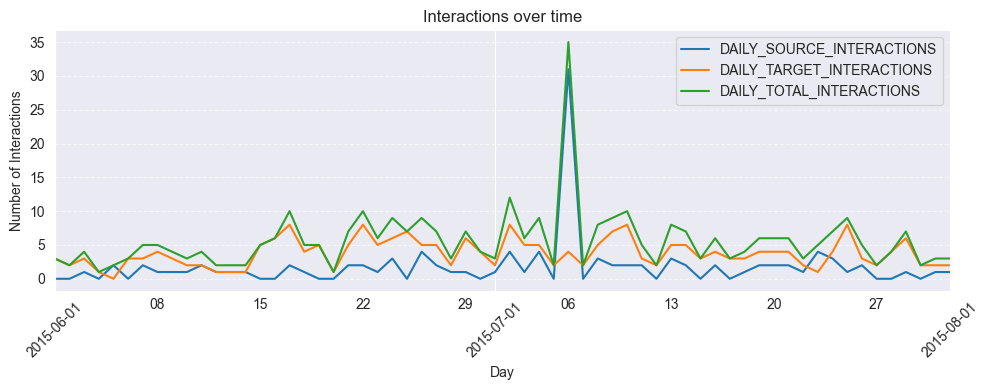

In [5]:
print("There are", len(focused_df["SOURCE_SUBREDDIT"].unique()), "different subreddits acting as source.")
print("There are", len(focused_df["TARGET_SUBREDDIT"].unique()), "different subreddits acting as target.")

# Count the number of daily interactions across all considered subreddits
daily_interaction_df = construct_daily_interaction_df(focused_df, KEYWORD, TIME_WINDOW)

# Plot
fig, ax = plt.subplots(figsize=(10,4))

daily_interaction_df[["DAILY_SOURCE_INTERACTIONS",
                      "DAILY_TARGET_INTERACTIONS",
                      "DAILY_TOTAL_INTERACTIONS"]].plot(ax=ax)

# ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Interactions over time")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Interactions")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

We can see that a clear outbreak appears at the beginning of July 2015. We can also see that overall there are more targeted subreddits than source (a smaller amount of subreddits target more other subreddits). But during the outbreak, the number of source subreddits explodes, indicating a lot more different subreddits linked to the same (small) amount of target subreddits. This could be a toxic wave coming from various different communities towards a particular subreddit.

### Number of interactions (as source and target) for each subreddit 

To further analyze which subreddits are potential victims and prosecutors, we show the amount of interactions (as source and as target) for the 8 most interactive subreddits.

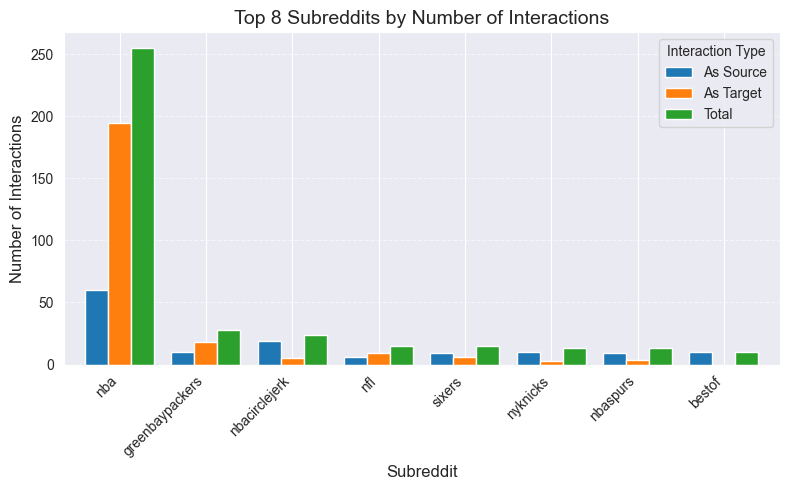

In [6]:
# Count the number of interaction as source and as target for each subreddit
sr_interaction_count_df = construct_interaction_count_df(focused_df)

# Choose the number of subreddits to plot
NB_TO_PLOT = 8

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

sr_interaction_count_df.head(NB_TO_PLOT).plot(
    x="SUBREDDIT",
    y=["SOURCE_INTERACTIONS", "TARGET_INTERACTIONS", "TOTAL_INTERACTIONS"],
    kind="bar",
    width=0.8,
    ax=ax
)

ax.set_title("Top " + str(NB_TO_PLOT) + " Subreddits by Number of Interactions", fontsize=14)
ax.set_xlabel("Subreddit", fontsize=12)
ax.set_ylabel("Number of Interactions", fontsize=12)
ax.set_xticklabels(sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"], rotation=45, ha="right")
ax.legend(["As Source", "As Target", "Total"], title="Interaction Type")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

A clear trend of links towards the 'nba' subreddit shows up, and some others like the 'nbacirclejerk' appears as one of the most targeting subreddit. Although, the balance between subreddits is not equitable and therefore if any toxic outbreak were to be happening, this would mean many attackers are implied rather than a specific subreddit. This makes the analysis more complicated, as we have to analyze the evolution interactions for each small subreddit separately. This is because we need to see if it is indeed a change in their behaviour or a recurrent interaction between the target and the source. 

### Number of negative daily interactions across each subreddit 

We now study the interactions themselves to see if they are negative and/or toxic based on as many criteria as wanted. Here, we take:
- 'LINK_SENTIMENT' == -1,
- 'COMPOUND_SENTIMENT_CALCULATED_BY_VADER' <= -0.5,
- 'NEGATIVE_SENTIMENT_CALCULATED_BY_VADER' >= 0.1

These are very non-strict thresholds, for the sake of the example.  

In [ ]:
# Count the number of negative daily interactions across all considered subreddits
CRITERION = ["LINK_SENTIMENT",
             "TOXICITY_CAT",
             "TOXICITY_SCORE",
             "TOXICITY_SCORE_ROLLZ"
             ]
THRESHOLDS = [0,
              0.5,
              0.5,
              0.10
              ]
UPPER = [True,
         True,
         False,
         False
         ]
daily_neg_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="DAY")

# Plot
fig, ax = plt.subplots(figsize=(10,4))

daily_neg_interaction_df.plot(ax=ax)

ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Negative Interactions over time")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Negative Interactions")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Show dataframe for further investigation
daily_neg_interaction_df

It appears that during the outbreak, 28 of the 35 interactions have a negative sentiment calculated by VADER above 0.1, but only 1 interaction has a negative link_sentiment. In this example, we would tend to say this is not a major negative outbreak, and that these results are non-conclusive. This could be an outbreak with regular amount of toxicity, or simply a non-negative outbreak. Note again that this should and will be further analyzed to quantify the regular amount of toxicity and that relevance of criteria should be investigated (causal analysis in P3).

### Number of interactions (as source and target) for each subreddit

Finally, we add a plot showing the number of negative interactions for each subreddit which allow us to highlight which subreddit is associated with negative links.

In [ ]:
# Count the number of negative interactions for each considered subreddit

# Compute negative interactions as source
sr_neg_source_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="SOURCE_SUBREDDIT")
# Compute negative interactions as target
sr_neg_target_interaction_df = construct_neg_interaction_df(focused_df, 
                                                        time_window=TIME_WINDOW, 
                                                        criteria=CRITERION, 
                                                        threshold=THRESHOLDS, 
                                                        upper=UPPER,
                                                        groupby_type="TARGET_SUBREDDIT")
# Add interactions and sort them by total
sr_neg_interaction_df = smart_df_add(sr_neg_source_interaction_df, sr_neg_target_interaction_df)
sr_neg_interaction_df["TOTAL_NEGATIVE_INTERACTIONS"] = sr_neg_interaction_df.sum(axis=1)
sr_neg_interaction_df = sr_neg_interaction_df.sort_values(by="TOTAL_NEGATIVE_INTERACTIONS", ascending=False)

# Choose the number of subreddits to plot
NB_TO_PLOT = 9

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

sr_neg_interaction_df.head(NB_TO_PLOT).plot(
    y=sr_neg_interaction_df.columns[:-1],
    kind="bar",
    width=0.8,
    ax=ax
)

ax.set_title("Top " + str(NB_TO_PLOT) + " Subreddits by Number of Interactions", fontsize=14)
ax.set_xlabel("Subreddit", fontsize=12)
ax.set_ylabel("Number of Interactions", fontsize=12)
ax.set_xticklabels(sr_interaction_count_df.head(NB_TO_PLOT)["SUBREDDIT"], rotation=45, ha="right")
ax.legend(sr_neg_interaction_df.columns, title="Interaction Type")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Again, the 'nba' subreddit stands out which makes sense as it was the most interactive during this period. We can see that the total amount of negative interactions goes up to roughly 70 over 250 total interactions based on the negative VADER criterion, and only up to 20 using link_sentiment. As explained above, habitual toxic interaction ratio and relevance of each criterion should be further investigated and motivated. 

We therefore cannot assess if it was a negative outbreak for the 'nba' subreddit or not, based on the current results. This is still a good example of how we aim to find potential patient-0, as a first step in the whole process. We emphasize the complexity of this task which still needs deeper analysis (see causal analysis next), and we are aware that a more detailed exploration is needed (pursued in P3).

## Causal Analysis (P3)

This allows us to perform a more trustful study based on the prior beliefs obtained in the previous section. This includes assessing relevance of criteria and thresholds and global toxic trends of each subreddit in this context among others.